# Gestión de proyectos de inteligencia artificial
## Semana 6, Módulo 2, Actividad 5
## Tomás Olivares - 25/10/26

### Actividad 5: Gestión de datos, entrenamiento y MLflow

**Objetivo:** preparar un dataset público, comparar dos clasificadores, ajustar hiperparámetros y registrar resultados en MLflow.

Seleccioné el dataset [Wisconsin Diagnostic Breast Cancer](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html?utm_source=chatgpt.com), disponible en scikit-learn y en UCI. La variable objetivo es el diagnóstico (maligno/benigno). El uso es académico y no debe emplearse para diagnósticos médicos.

## 1. Importaciones y preparación del dataset

In [40]:
%pip install -q mlflow scikit-learn pandas matplotlib

In [41]:
from pathlib import Path
import json, pickle, shutil, zipfile, warnings
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from mlflow.tracking import MlflowClient
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path("/content")
DATA_DIR = ROOT / "datos" / "datos_limp"
EVID_DIR = ROOT / "evidencias"
DATA_DIR.mkdir(parents=True, exist_ok=True)
EVID_DIR.mkdir(parents=True, exist_ok=True)
DATA_FILE = DATA_DIR / "breast_cancer_limpio.csv"
TRACKING_URI = "sqlite:////content/mlflow.db"
EXPERIMENT_NAME = "Actividad5_Comparacion_Clasificadores"
print("Rutas preparadas:", DATA_FILE)

Rutas preparadas: /content/datos/datos_limp/breast_cancer_limpio.csv


In [42]:
%pip install -r /content/requirements.txt

## 2. Preparación y calidad del dataset
Se reutiliza el CSV limpio si existe. En una sesión nueva de Colab, se reconstruye a partir del dataset Wisconsin incluido en scikit-learn.

Se reutilizó el CSV limpio existente.
Dimensiones: (569, 32)
Nulos: 0
Duplicados exactos: 0


,registros
diagnostico,
benigno,357
maligno,212


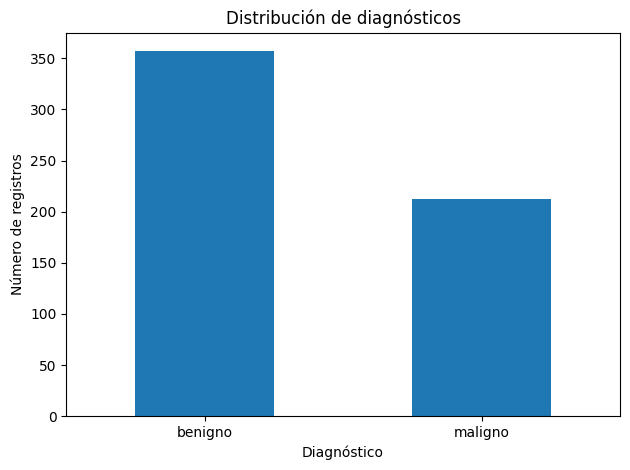

In [43]:
if DATA_FILE.exists():
    df = pd.read_csv(DATA_FILE)
    print("Se reutilizó el CSV limpio existente.")
else:
    datos = load_breast_cancer(as_frame=True)
    df = datos.data.copy()
    df["diagnostico"] = pd.Series(datos.target, index=df.index).map({0: "maligno", 1: "benigno"})
    df.insert(0, "id_registro", range(1, len(df) + 1))
    df.to_csv(DATA_FILE, index=False)
    print("Se creó el CSV desde scikit-learn.")

df.columns = [str(c).strip() for c in df.columns]
if "diagnostico" not in df.columns:
    raise ValueError("Falta la columna 'diagnostico'.")
mapa = {"malignant":"maligno", "maligno":"maligno", "0":"maligno",
        "benign":"benigno", "benigno":"benigno", "1":"benigno"}
df["diagnostico"] = df["diagnostico"].astype(str).str.strip().str.lower().map(mapa)
if df["diagnostico"].isna().any():
    raise ValueError("Hay diagnósticos vacíos o no reconocidos.")
if "id_registro" not in df.columns:
    df.insert(0, "id_registro", range(1, len(df) + 1))

print("Dimensiones:", df.shape)
print("Nulos:", int(df.isna().sum().sum()))
print("Duplicados exactos:", int(df.duplicated().sum()))
display(df["diagnostico"].value_counts().rename_axis("diagnostico").to_frame("registros"))
if df.isna().any().any():
    raise ValueError("Hay valores nulos; deben tratarse antes de entrenar.")
df["diagnostico"].value_counts().plot(kind="bar", title="Distribución de diagnósticos")
plt.xlabel("Diagnóstico"); plt.ylabel("Número de registros")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 3. Entrenamiento, Grid Search y registro en MLflow
Se usa test del 20%, `random_state=42` y validación cruzada estratificada de cinco particiones. La búsqueda optimiza F1. Cada modelo registra métricas, parámetros y un archivo Pickle como artefacto.

In [44]:
X = df.drop(columns=["diagnostico", "id_registro"], errors="ignore").select_dtypes(include="number")
y = df["diagnostico"].map({"maligno": 0, "benigno": 1})
if X.empty or y.isna().any():
    raise ValueError("Revisa las variables predictoras y la variable objetivo.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelos = {
    "Regresion_Logistica": (
        Pipeline([("escalador", StandardScaler()),
                  ("modelo", LogisticRegression(max_iter=5000, random_state=42))]),
        {"modelo__C": [0.1, 1.0, 10.0],
         "modelo__class_weight": [None, "balanced"]}
    ),
    "Random_Forest": (
        Pipeline([("modelo", RandomForestClassifier(random_state=42, n_jobs=-1))]),
        {"modelo__n_estimators": [100, 200],
         "modelo__max_depth": [None, 5, 10],
         "modelo__min_samples_leaf": [1, 2]}
    )
}

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)
client = MlflowClient()
resultados_lista = []

for nombre, (pipeline, parametros) in modelos.items():
    print("Entrenando:", nombre)
    busqueda = GridSearchCV(pipeline, parametros, scoring="f1", cv=cv, n_jobs=-1, refit=True)
    busqueda.fit(X_train, y_train)
    mejor = busqueda.best_estimator_
    pred = mejor.predict(X_test)
    prob = mejor.predict_proba(X_test)[:, 1]
    metricas = {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, prob),
        "cv_f1_mean": busqueda.best_score_
    }
    with mlflow.start_run(run_name=nombre) as run:
        run_id = run.info.run_id
        mlflow.log_params({k: str(v) for k, v in busqueda.best_params_.items()})
        mlflow.log_param("random_state", 42)
        mlflow.log_param("validacion_cruzada", "5-fold stratified")
        mlflow.log_param("test_size", 0.20)
        mlflow.log_metrics({k: float(v) for k, v in metricas.items()})
        archivo_modelo = ROOT / f"{nombre}.pkl"
        with open(archivo_modelo, "wb") as f:
            pickle.dump(mejor, f)
        mlflow.log_artifact(str(archivo_modelo), artifact_path="modelo")
    resultados_lista.append({"modelo": nombre, **metricas,
        "mejores_hiperparametros": json.dumps(busqueda.best_params_, ensure_ascii=False),
        "run_id": run_id})

resultados = pd.DataFrame(resultados_lista)
resultados.to_csv(ROOT / "resultados_modelos.csv", index=False)
display(resultados.drop(columns=["run_id"]))
print("Modelos y métricas registrados en MLflow.")

Entrenando: Regresion_Logistica
Entrenando: Random_Forest


,modelo,accuracy,precision,recall,f1,roc_auc,cv_f1_mean,mejores_hiperparametros
0,Regresion_Logistica,0.973684,0.972603,0.986111,0.979310,0.995701,0.986116,"{""modelo__C"": 0.1, ""modelo__class_weight"": null}"
1,Random_Forest,0.956140,0.958904,0.972222,0.965517,0.993056,0.970181,"{""modelo__max_depth"": 5, ""modelo__min_samples_..."


Modelos y métricas registrados en MLflow.


## 4. Consulta consolidada de MLflow
Consulta el historial sin crear nuevas ejecuciones. La tabla resumen muestra la ejecución `FINISHED` más reciente de cada modelo. Las ejecuciones antiguas se conservan para auditoría.

In [45]:
mlflow.set_tracking_uri(TRACKING_URI)
client = MlflowClient()
experimento = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if experimento is None:
    raise RuntimeError("No se encontró el experimento de MLflow.")
runs = mlflow.search_runs(experiment_ids=[experimento.experiment_id], output_format="pandas")
if runs.empty:
    raise RuntimeError("No hay ejecuciones en el experimento.")

print("Historial de ejecuciones:", len(runs))
display(runs[["tags.mlflow.runName", "status", "start_time", "run_id"]]
        .sort_values("start_time", ascending=False).reset_index(drop=True))
exitosas = runs[runs["status"] == "FINISHED"].sort_values("start_time", ascending=False)
exitosas = exitosas.drop_duplicates("tags.mlflow.runName", keep="first")
cols = ["tags.mlflow.runName", "status", "metrics.accuracy", "metrics.precision",
        "metrics.recall", "metrics.f1", "metrics.roc_auc", "metrics.cv_f1_mean"]
cols = [c for c in cols if c in exitosas.columns]
print("Resumen sin ejecuciones repetidas:")
display(exitosas[cols].reset_index(drop=True))

for _, fila in exitosas.iterrows():
    run = client.get_run(fila["run_id"])
    print(f"\nModelo: {fila['tags.mlflow.runName']} | Run ID: {fila['run_id']}")
    print("Parámetros:", run.data.params)
    print("Artefactos:", client.list_artifacts(run.info.run_id, "modelo"))

Historial de ejecuciones: 6


,tags.mlflow.runName,status,start_time,run_id
0,Random_Forest,FINISHED,2026-10-26 04:12:35.501000+00:00,415a07aee6a542588aa55c8042df111b
1,Regresion_Logistica,FINISHED,2026-10-26 04:12:16.912000+00:00,80f49ea607784e5fb4b7284b39362ecc
2,Random_Forest,FINISHED,2026-10-26 03:47:20.087000+00:00,ac77b43a26944351a65b0188302bd4b3
3,Regresion_Logistica,FINISHED,2026-10-26 03:47:16.464000+00:00,e6b76ad7cfc7440bae4c3b0f242a8a31
4,Random_Forest,FAILED,2026-10-26 03:45:15.676000+00:00,421c38b71499431ca3c0492de50eaf22
5,Regresion_Logistica,FINISHED,2026-10-26 03:45:07.308000+00:00,58a6046ec1b54ea1bc0b6e4367d08147


Resumen sin ejecuciones repetidas:


,tags.mlflow.runName,status,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1,metrics.roc_auc,metrics.cv_f1_mean
0,Random_Forest,FINISHED,0.956140,0.958904,0.972222,0.965517,0.993056,0.970181
1,Regresion_Logistica,FINISHED,0.973684,0.972603,0.986111,0.979310,0.995701,0.986116



Modelo: Random_Forest | Run ID: 415a07aee6a542588aa55c8042df111b
Parámetros: {'modelo__max_depth': '5', 'modelo__min_samples_leaf': '2', 'modelo__n_estimators': '100', 'random_state': '42', 'validacion_cruzada': '5-fold stratified', 'test_size': '0.2'}
Artefactos: [<FileInfo: file_size=246683, is_dir=False, path='modelo/Random_Forest.pkl'>]

Modelo: Regresion_Logistica | Run ID: 80f49ea607784e5fb4b7284b39362ecc
Parámetros: {'modelo__C': '0.1', 'modelo__class_weight': 'None', 'random_state': '42', 'validacion_cruzada': '5-fold stratified', 'test_size': '0.2'}
Artefactos: [<FileInfo: file_size=2682, is_dir=False, path='modelo/Regresion_Logistica.pkl'>]


## 5. Comparación gráfica de resultados en test

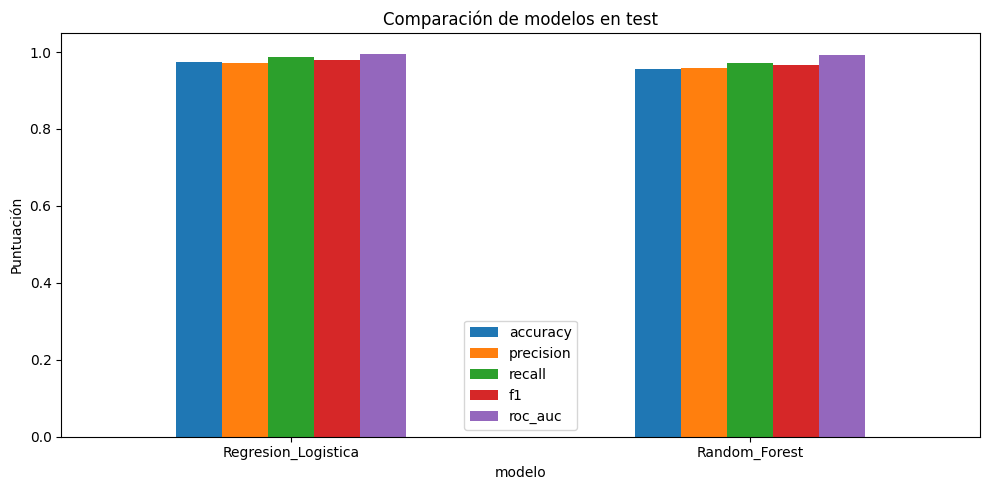

In [46]:
metricas_grafica = ["accuracy", "precision", "recall", "f1", "roc_auc"]
ax = resultados.set_index("modelo")[metricas_grafica].plot(kind="bar", figsize=(10, 5))
ax.set_ylim(0, 1.05)
ax.set_ylabel("Puntuación")
ax.set_title("Comparación de modelos en test")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 6. Interpretación
En la ejecución previa, Regresión Logística obtuvo F1 = 0.9793 y ROC-AUC = 0.9957; Random Forest obtuvo F1 = 0.9655 y ROC-AUC = 0.9931. En esa partición de prueba, Regresión Logística mostró el mejor equilibrio entre precisión y recall y la mayor puntuación F1.

Los resultados dependen de la partición de prueba (`random_state=42`) y no garantizan el mismo rendimiento con otros datos. El dataset es académico y no debe emplearse para decisiones clínicas.

## 7. Exportación de evidencias
Genera un CSV, un TXT de detalle y un ZIP con evidencias y modelos Pickle.

In [47]:
runs_ok = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id],
    filter_string="attributes.status = 'FINISHED'"
)
runs_ok = runs_ok.sort_values("start_time", ascending=False).drop_duplicates(
    "tags.mlflow.runName", keep="first"
)
cols = ["tags.mlflow.runName", "status", "metrics.accuracy", "metrics.precision",
        "metrics.recall", "metrics.f1", "metrics.roc_auc", "metrics.cv_f1_mean"]
cols = [c for c in cols if c in runs_ok.columns]
runs_ok[cols].to_csv(EVID_DIR / "mlflow_resultados.csv", index=False)

with open(EVID_DIR / "mlflow_detalle.txt", "w", encoding="utf-8") as f:
    for _, fila in runs_ok.iterrows():
        run = client.get_run(fila["run_id"])
        f.write(f"Modelo: {fila['tags.mlflow.runName']}\n")
        f.write(f"Estado: {run.info.status}\nRun ID: {run.info.run_id}\n")
        f.write(f"Parámetros: {run.data.params}\nMétricas: {run.data.metrics}\n")
        f.write("Artefactos:\n")
        for art in client.list_artifacts(run.info.run_id):
            f.write(f"  {art.path}\n")
        f.write("\n")

archivo_resultados = ROOT / "resultados_modelos.csv"
if archivo_resultados.exists():
    shutil.copy2(archivo_resultados, EVID_DIR / "resultados_modelos.csv")

zip_path = ROOT / "evidencias_actividad5.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in EVID_DIR.iterdir():
        if archivo.is_file():
            z.write(archivo, arcname=f"evidencias/{archivo.name}")
    for nombre in ["Regresion_Logistica.pkl", "Random_Forest.pkl"]:
        archivo = ROOT / nombre
        if archivo.exists():
            z.write(archivo, arcname=nombre)

print("Evidencias:", [p.name for p in EVID_DIR.iterdir() if p.is_file()])
print("ZIP generado:", zip_path)

Evidencias: ['mlflow_detalle.txt', 'reporte_Regresion_Logistica.csv', 'mlflow_resultados.csv', 'resultados_modelos.csv']
ZIP generado: /content/evidencias_actividad5.zip


In [48]:
from pathlib import Path
import zipfile

zip_path = Path("/content/evidencias_actividad5.zip")

print("Existe:", zip_path.exists())

if zip_path.exists():
    with zipfile.ZipFile(zip_path, "r") as z:
        print("\nContenido del ZIP:")
        for archivo in z.namelist():
            print(archivo)

        print("\nZIP íntegro:", z.testzip() is None)

Existe: True

Contenido del ZIP:
evidencias/mlflow_detalle.txt
evidencias/reporte_Regresion_Logistica.csv
evidencias/mlflow_resultados.csv
evidencias/resultados_modelos.csv
Regresion_Logistica.pkl
Random_Forest.pkl

ZIP íntegro: True
